In [1]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()
con.sql("""
    CREATE VIEW v AS
    SELECT * FROM read_parquet('../data/clean/*/*/violations.parquet')
""")

CountBIGINT


In [2]:
con.sql("""
    SELECT count(*) AS tickets,
           count(DISTINCT source_month) AS months,
           min(issued_at_utc) AS first,
           max(issued_at_utc) AS last,
           count(DISTINCT (latitude, longitude)) AS blocks
    FROM v
""").df()

,tickets,months,first,last,blocks
0,4479211,46,2023-01-01 00:00:00-05:00,2026-10-31 13:38:00-04:00,10064


In [3]:
con.sql("""
    SELECT violation_code, any_value(violation_desc) AS description,
           count(*) AS tickets,
           round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct
    FROM v GROUP BY 1 ORDER BY tickets DESC LIMIT 15
""").df()

,violation_code,description,tickets,pct
0,P281,FAIL TO DISPLAY A MULTISPACE METER RECEIPT,547022,12.2
1,P170,FAILURE TO DISPLAY CURRENT TAGS,393120,8.8
2,P012,DISOBEYING OFFICIAL SIGN,384270,8.6
3,P173,NO PARKING STREET CLEANING,305305,6.8
4,P055,NO PARKING ANYTIME,271732,6.1
5,P003,RESIDENTIAL PERMIT PKING BEYOND LIMIT W/O PERMIT,220101,4.9
6,P259,NO STOPPING OR STANDING IN PM RUSH HOUR ZONE,218715,4.9
7,P269,NO STANDING ANYTIME,213642,4.8
8,P168,NO FRONT TAGS.,168222,3.8
9,P039,PARK AT EXPIRED METER,157321,3.5


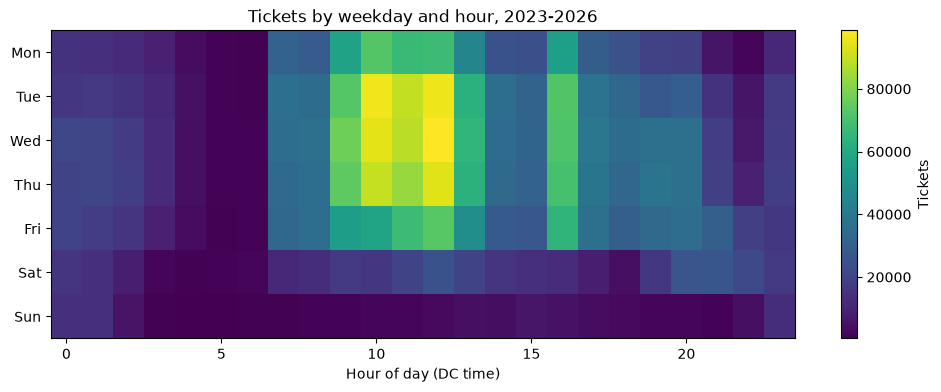

In [4]:
df = con.sql("""
    SELECT issued_local_weekday AS weekday, issued_local_hour AS hour, count(*) AS tickets
    FROM v GROUP BY 1, 2
""").df()
grid = df.pivot(index="weekday", columns="hour", values="tickets")

plt.figure(figsize=(12, 4))
plt.imshow(grid, aspect="auto", cmap="viridis")
plt.yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
plt.xlabel("Hour of day (DC time)")
plt.colorbar(label="Tickets")
plt.title("Tickets by weekday and hour, 2023-2026")
plt.show()

In [5]:
con.sql("""
    SELECT latitude, longitude, count(*) AS tickets
    FROM v WHERE is_geocoded
    GROUP BY 1, 2 ORDER BY tickets DESC LIMIT 20
""").df()

,latitude,longitude,tickets
0,38.877,-77.020,20498
1,38.880,-77.024,19684
2,38.906,-77.040,15972
3,38.892,-77.030,15485
4,38.878,-77.008,15397
5,38.907,-77.040,15261
6,38.910,-77.044,14754
7,38.925,-77.040,14297
8,38.903,-77.063,14254
9,38.915,-76.984,14041


In [6]:
con.sql("""
    WITH per_block AS (
        SELECT count(*) AS tickets FROM v WHERE is_geocoded GROUP BY latitude, longitude
    ),
    ranked AS (
        SELECT tickets, percent_rank() OVER (ORDER BY tickets DESC) AS pct_rank
        FROM per_block
    )
    SELECT count(*) AS blocks,
           median(tickets) AS median_tickets_per_block,
           sum(tickets) FILTER (WHERE pct_rank < 0.10) / sum(tickets) AS share_in_top_10pct
    FROM ranked
""").df()

,blocks,median_tickets_per_block,share_in_top_10pct
0,10063,51.0,0.709452


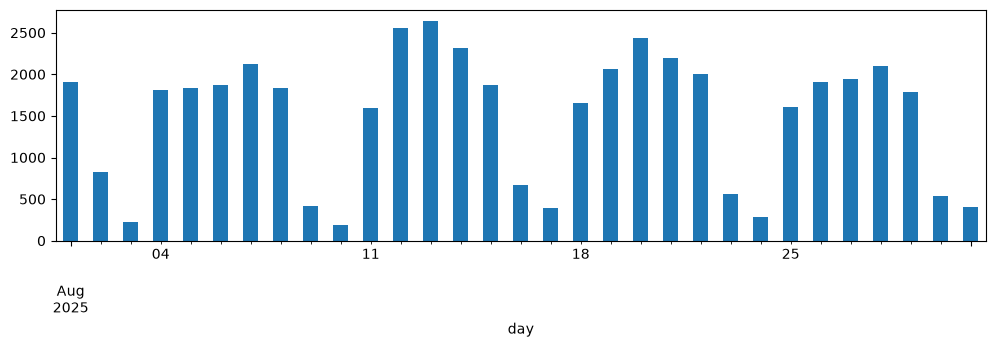

In [7]:
df = con.sql("""
    SELECT CAST(issued_at_utc AT TIME ZONE 'America/New_York' AS DATE) AS day, count(*) AS tickets
    FROM v WHERE source_month = '2025-08'
    GROUP BY 1 ORDER BY 1
""").df()
df.plot(x="day", y="tickets", kind="bar", figsize=(12, 3), legend=False)
plt.show()

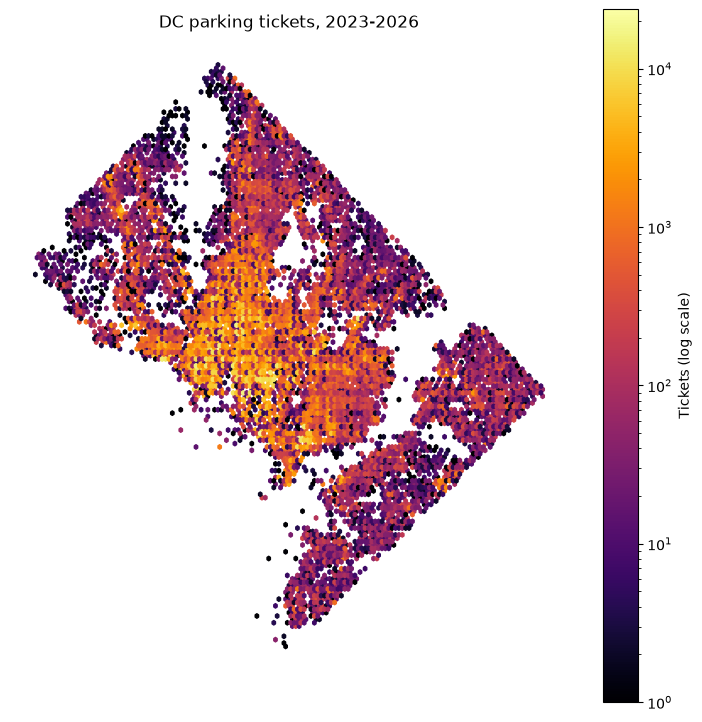

In [8]:
import math

pts = con.sql("""
    SELECT longitude, latitude FROM v WHERE is_geocoded
""").df()

fig, ax = plt.subplots(figsize=(9, 9))
hb = ax.hexbin(pts.longitude, pts.latitude, gridsize=150, bins="log", cmap="inferno", mincnt=1)
ax.set_aspect(1 / math.cos(math.radians(38.9)))
fig.colorbar(hb, label="Tickets (log scale)")
ax.set_title("DC parking tickets, 2023-2026")
ax.set_axis_off()
plt.show()

In [9]:
import json, glob

xy, latlon = set(), set()
for path in glob.glob("../data/raw/year=2026/month=09/page_*.json"):
    for f in json.load(open(path))["features"]:
        a = f["attributes"]
        if a.get("XCOORD") and a.get("LATITUDE"):
            xy.add((a["XCOORD"], a["YCOORD"]))
            latlon.add((a["LATITUDE"], a["LONGITUDE"]))
print(f"distinct XY: {len(xy):,}   distinct lat/lon: {len(latlon):,}")

distinct XY: 6,238   distinct lat/lon: 4,655


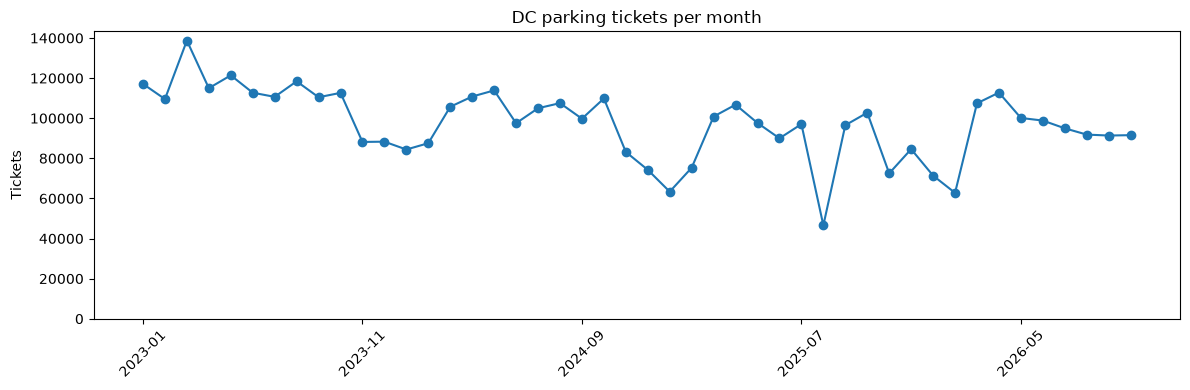

In [10]:
df = con.sql("""
    SELECT source_month, count(*) AS tickets
    FROM v GROUP BY 1 ORDER BY 1
""").df()

ax = df.plot(x="source_month", y="tickets", figsize=(12, 4), legend=False, marker="o")
ax.set_ylim(bottom=0)
ax.set_xlabel("")
ax.set_ylabel("Tickets")
ax.set_title("DC parking tickets per month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()